In [1]:
import pandas as pd, numpy as np
import os
for root, _, files in os.walk('/kaggle/input'):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

path = "/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv"
df = pd.read_csv(path)
print("Raw shape:", df.shape)
print(df.columns.tolist())

Raw shape: (162421, 3)
['Unnamed: 0', 'product', 'narrative']


In [3]:
df = df[['product', 'narrative']]

In [4]:
print("\nNulls:\n", df.isnull().sum())
df = df.dropna()


Nulls:
 product       0
narrative    10
dtype: int64


In [5]:
print("\nDuplicates:", df.duplicated(subset='narrative').sum())
df = df.drop_duplicates(subset='narrative').reset_index(drop=True)
print("Shape after cleaning:", df.shape)


Duplicates: 37939
Shape after cleaning: (124472, 2)


In [6]:
print("\n", df['product'].value_counts())
print("\n", df['product'].value_counts(normalize=True).round(3))


 product
credit_reporting       56240
debt_collection        21057
mortgages_and_loans    18723
credit_card            14983
retail_banking         13469
Name: count, dtype: int64

 product
credit_reporting       0.452
debt_collection        0.169
mortgages_and_loans    0.150
credit_card            0.120
retail_banking         0.108
Name: proportion, dtype: float64


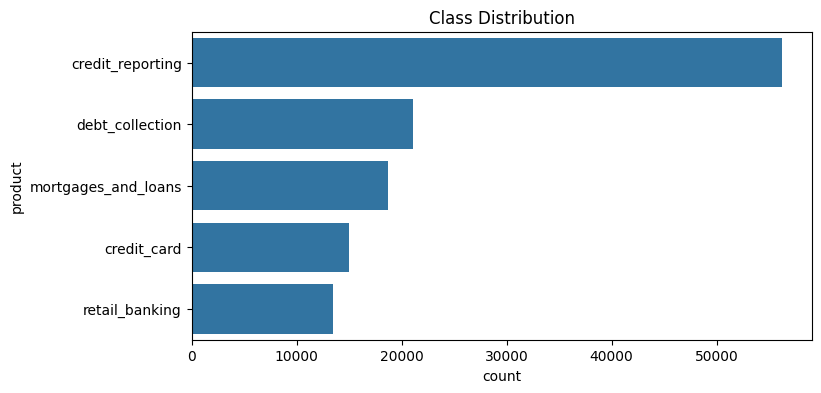

In [7]:
plt.figure(figsize=(8,4))
sns.countplot(y='product', data=df, order=df['product'].value_counts().index)
plt.title("Class Distribution"); plt.show()


 count    124472.000000
mean         87.170022
std         110.931857
min           1.000000
25%          30.750000
50%          58.000000
75%         104.000000
max        2685.000000
Name: n_words, dtype: float64
95th percentile: 253.0


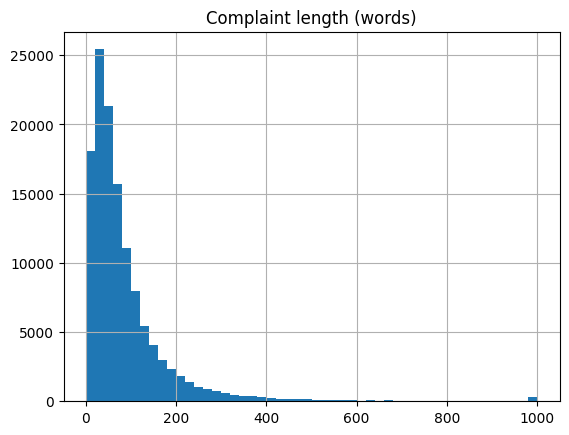

In [8]:
df['n_words'] = df['narrative'].str.split().str.len()
print("\n", df['n_words'].describe())
print("95th percentile:", df['n_words'].quantile(0.95))

df['n_words'].clip(upper=1000).hist(bins=50)
plt.title("Complaint length (words)"); plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [10]:
le = LabelEncoder()
df['label'] = le.fit_transform(df['product'])
n_classes = len(le.classes_)
print(dict(enumerate(le.classes_)))

{0: 'credit_card', 1: 'credit_reporting', 2: 'debt_collection', 3: 'mortgages_and_loans', 4: 'retail_banking'}


In [11]:
train_df, temp_df = train_test_split(
    df, test_size=0.2, stratify=df['label'], random_state=42)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42)

In [12]:
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Test:", test_df.shape)
print(train_df['label'].value_counts(normalize=True).round(3).sort_index())
print(test_df['label'].value_counts(normalize=True).round(3).sort_index())

Train: (99577, 4) | Val: (12447, 4) | Test: (12448, 4)
label
0    0.120
1    0.452
2    0.169
3    0.150
4    0.108
Name: proportion, dtype: float64
label
0    0.120
1    0.452
2    0.169
3    0.150
4    0.108
Name: proportion, dtype: float64


In [13]:
w = compute_class_weight('balanced',
                         classes=np.unique(train_df['label']),
                         y=train_df['label'])
class_weight = dict(enumerate(w))
print("Class weights:", {le.classes_[k]: round(v, 2) for k, v in class_weight.items()})

Class weights: {'credit_card': np.float64(1.66), 'credit_reporting': np.float64(0.44), 'debt_collection': np.float64(1.18), 'mortgages_and_loans': np.float64(1.33), 'retail_banking': np.float64(1.85)}


In [14]:
VOCAB = 20000
MAXLEN = 200

tok = Tokenizer(num_words=VOCAB, oov_token="<OOV>")
tok.fit_on_texts(train_df['narrative'])

def to_seq(texts):
    return pad_sequences(tok.texts_to_sequences(texts),
                         maxlen=MAXLEN, padding='post', truncating='post')

In [15]:
X_train = to_seq(train_df['narrative']); y_train = train_df['label'].values
X_val   = to_seq(val_df['narrative']);   y_val   = val_df['label'].values
X_test  = to_seq(test_df['narrative']);  y_test  = test_df['label'].values

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("Unique words found:", len(tok.word_index))
print("Example:", X_train[0][:20])

X_train: (99577, 200) | X_val: (12447, 200) | X_test: (12448, 200)
Unique words found: 41596
Example: [  16   17  145  384  155  257    2  411   11  239  543    2    3   11
   22   72   42  268  190 1299]


In [17]:
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix)
import time

In [18]:
EMB_DIM = 128
UNITS = 64

results, histories, preds_store = {}, {}, {}

def build_model(rnn_layer, name):
    m = models.Sequential([
        layers.Input(shape=(MAXLEN,)),
        layers.Embedding(VOCAB, EMB_DIM, mask_zero=True),
        rnn_layer(UNITS),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation='softmax')
    ], name=name)
    m.compile(loss='sparse_categorical_crossentropy',
              optimizer=optimizers.Adam(1e-3, clipnorm=1.0),
              metrics=['accuracy'])
    return m

def train_and_eval(rnn_layer, name, epochs=8):
    model = build_model(rnn_layer, name)
    model.summary()
    es = callbacks.EarlyStopping(monitor='val_loss', patience=2,
                                 restore_best_weights=True)
    t0 = time.time()
    h = model.fit(X_train, y_train,
                  validation_data=(X_val, y_val),
                  epochs=epochs, batch_size=128,
                  class_weight=class_weight,
                  callbacks=[es], verbose=1)
    train_time = time.time() - t0

    probs = model.predict(X_test, batch_size=256, verbose=0)
    y_pred = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average='macro', zero_division=0)

    results[name] = {
        'accuracy': round(accuracy_score(y_test, y_pred), 4),
        'precision_macro': round(p, 4),
        'recall_macro': round(r, 4),
        'f1_macro': round(f1, 4),
        'train_time_sec': round(train_time)
    }
    histories[name] = h.history
    preds_store[name] = y_pred
    model.save(f"/kaggle/working/{name}.keras")

    print("\n", name, "->", results[name])
    print("\n", classification_report(y_test, y_pred, target_names=le.classes_, digits=3))

    plt.figure(figsize=(6, 5))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Confusion Matrix - {name}")
    plt.ylabel("True"); plt.xlabel("Predicted"); plt.show()
    return model

I0000 00:00:1793477840.285837      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793477840.289721      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,893 (9.97 MB)

 Trainable params: 2,613,893 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 17s 15ms/step - accuracy: 0.7333 - loss: 0.7541 - val_accuracy: 0.8032 - val_loss: 0.5855
Epoch 2/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8269 - loss: 0.5103 - val_accuracy: 0.8171 - val_loss: 0.5331
Epoch 3/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8430 - loss: 0.4501 - val_accuracy: 0.8240 - val_loss: 0.5181
Epoch 4/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8539 - loss: 0.4050 - val_accuracy: 0.8260 - val_loss: 0.4948
Epoch 5/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8625 - loss: 0.3699 - val_accuracy: 0.8242 - val_loss: 0.5367
Epoch 6/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8728 - loss: 0.3376 - val_accuracy: 0.8333 - val_loss: 0.5006

 LSTM -> {'accuracy': 0.8206, 'precision_macro': 0.7931, 'recall_macro': 0.8398, 'f1_macro': 0.8122, 'train_time_sec': 74}

                      precision    recall  f1-score   support

        credit_card      0.712     0.8

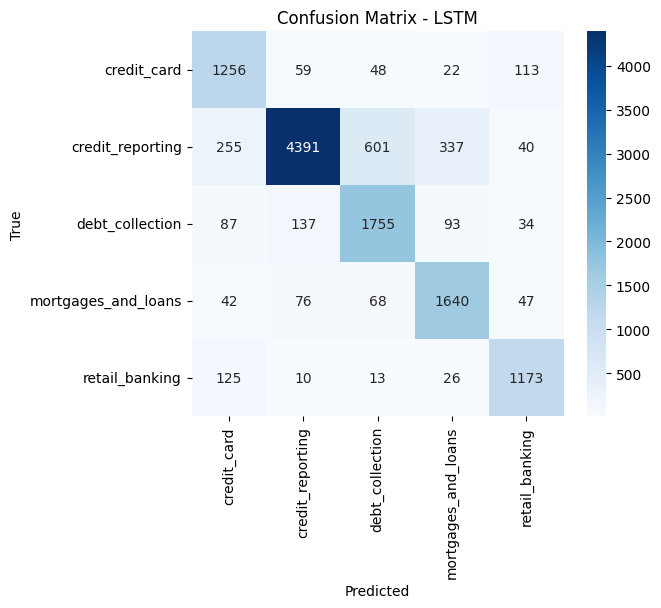

In [19]:
lstm_model = train_and_eval(layers.LSTM, "LSTM")

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,601,733 (9.92 MB)

 Trainable params: 2,601,733 (9.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.7194 - loss: 0.7448 - val_accuracy: 0.8236 - val_loss: 0.5111
Epoch 2/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8384 - loss: 0.4520 - val_accuracy: 0.8330 - val_loss: 0.4692
Epoch 3/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8558 - loss: 0.3893 - val_accuracy: 0.8316 - val_loss: 0.4926
Epoch 4/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8698 - loss: 0.3461 - val_accuracy: 0.8376 - val_loss: 0.4785

 GRU -> {'accuracy': 0.8373, 'precision_macro': 0.8067, 'recall_macro': 0.8508, 'f1_macro': 0.8257, 'train_time_sec': 47}

                      precision    recall  f1-score   support

        credit_card      0.729     0.838     0.780      1498
   credit_reporting      0.935     0.816     0.872      5624
    debt_collection      0.780     0.793     0.786      2106
mortgages_and_loans      0.774     0.902     0.833      1873
     retail_banking      0.815     0.905     0.858   

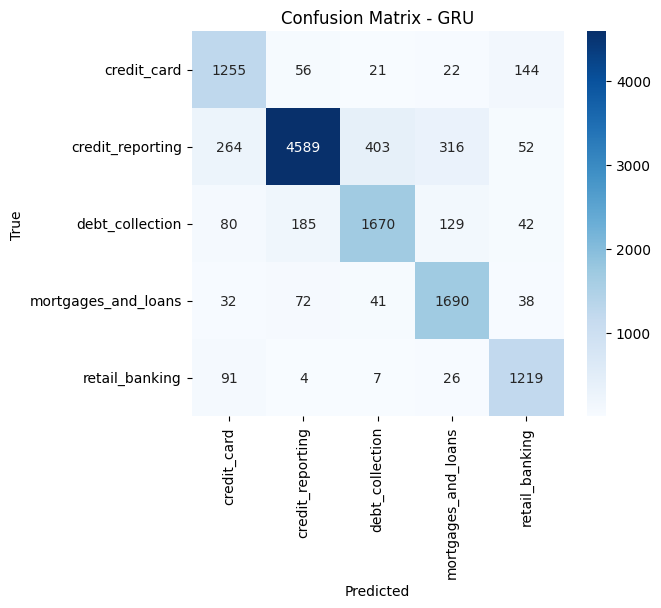

In [20]:
gru_model = train_and_eval(layers.GRU, "GRU")

In [22]:
import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding)

In [29]:
MODEL_NAME = "distilbert-base-uncased"
HF_MAXLEN = 256

hf_tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_ds(d):
    ds = Dataset.from_pandas(
        d[['narrative', 'label']].rename(columns={'narrative': 'text'}).reset_index(drop=True))
    return ds.map(lambda b: hf_tok(b['text'], truncation=True, max_length=HF_MAXLEN),
                  batched=True, remove_columns=['text'])

train_ds = make_ds(train_df)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)
print(train_ds, val_ds.num_rows, test_ds.num_rows)

Map:   0%|          | 0/99577 [00:00<?, ? examples/s]

Map:   0%|          | 0/12447 [00:00<?, ? examples/s]

Map:   0%|          | 0/12448 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 99577
}) 12447 12448


In [31]:
import time
from sklearn.metrics import f1_score

id2label = {i: c for i, c in enumerate(le.classes_)}
label2id = {c: i for i, c in id2label.items()}

bert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=n_classes, id2label=id2label, label2id=label2id)

cw_tensor = torch.tensor([class_weight[i] for i in range(n_classes)], dtype=torch.float)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = torch.nn.functional.cross_entropy(
            outputs.logits, labels, weight=cw_tensor.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "f1_macro": f1_score(p.label_ids, preds, average="macro")}

args = TrainingArguments(
    output_dir="/kaggle/working/distilbert_out",
    num_train_epochs=2,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=3e-5,
    weight_decay=0.01,
    warmup_steps=373,              
    eval_strategy="epoch",         
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1,
    fp16=True,
    report_to="none",
)

trainer = WeightedTrainer(
    model=bert, args=args,
    train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(hf_tok),
    compute_metrics=compute_metrics,
)

t0 = time.time()
trainer.train()
bert_train_time = time.time() - t0
print("Train time (s):", round(bert_train_time))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.438148,0.398034,0.828633,0.824793
2,0.358518,0.366643,0.857154,0.850827


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Train time (s): 2397


{'accuracy': 0.8527, 'precision_macro': 0.8287, 'recall_macro': 0.8609, 'f1_macro': 0.8433, 'train_time_sec': 2397}
                     precision    recall  f1-score   support

        credit_card      0.755     0.848     0.799      1498
   credit_reporting      0.931     0.840     0.883      5624
    debt_collection      0.765     0.829     0.796      2106
mortgages_and_loans      0.827     0.883     0.854      1873
     retail_banking      0.865     0.905     0.885      1347

           accuracy                          0.853     12448
          macro avg      0.829     0.861     0.843     12448
       weighted avg      0.859     0.853     0.854     12448



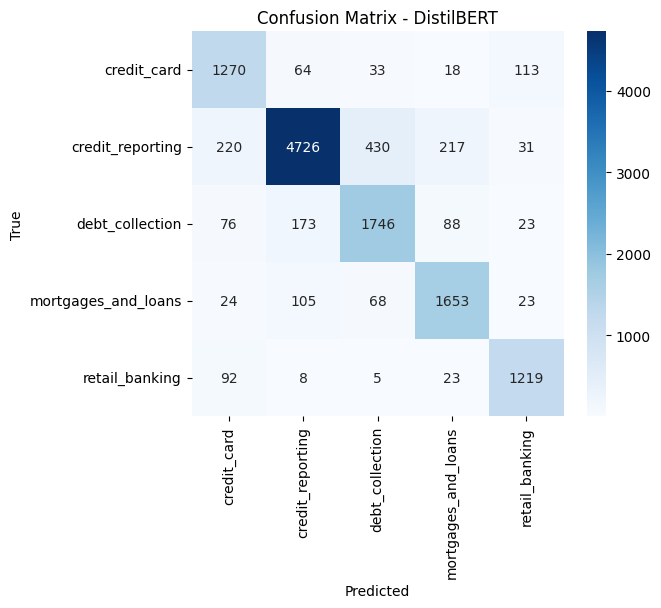

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [32]:
out = trainer.predict(test_ds)
y_pred = out.predictions.argmax(-1)

p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
results["DistilBERT"] = {
    'accuracy': round(accuracy_score(y_test, y_pred), 4),
    'precision_macro': round(p, 4), 'recall_macro': round(r, 4),
    'f1_macro': round(f1, 4), 'train_time_sec': round(bert_train_time)
}
preds_store["DistilBERT"] = y_pred
print(results["DistilBERT"])
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=3))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix - DistilBERT"); plt.ylabel("True"); plt.xlabel("Predicted"); plt.show()

trainer.save_model("/kaggle/working/distilbert_final")
hf_tok.save_pretrained("/kaggle/working/distilbert_final")

import json
json.dump(results, open("/kaggle/working/results.json", "w"), indent=2)

In [33]:
print(results.keys())

dict_keys(['LSTM', 'GRU', 'DistilBERT'])


Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,576,837 (9.83 MB)

 Trainable params: 2,576,837 (9.83 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
  6/778 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - accuracy: 0.2460 - loss: 1.6397

I0000 00:00:1793484024.757112     176 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


778/778 ━━━━━━━━━━━━━━━━━━━━ 24s 24ms/step - accuracy: 0.6282 - loss: 0.9692 - val_accuracy: 0.7618 - val_loss: 0.6880
Epoch 2/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.7648 - loss: 0.6922 - val_accuracy: 0.8036 - val_loss: 0.6289
Epoch 3/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.7923 - loss: 0.6235 - val_accuracy: 0.7929 - val_loss: 0.6422
Epoch 4/8
778/778 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.8054 - loss: 0.5963 - val_accuracy: 0.8080 - val_loss: 0.6489

 SimpleRNN -> {'accuracy': 0.7953, 'precision_macro': 0.7674, 'recall_macro': 0.7841, 'f1_macro': 0.7731, 'train_time_sec': 70}

                      precision    recall  f1-score   support

        credit_card      0.720     0.702     0.711      1498
   credit_reporting      0.878     0.823     0.849      5624
    debt_collection      0.741     0.693     0.716      2106
mortgages_and_loans      0.704     0.891     0.787      1873
     retail_banking      0.794     0.811     0.802      1

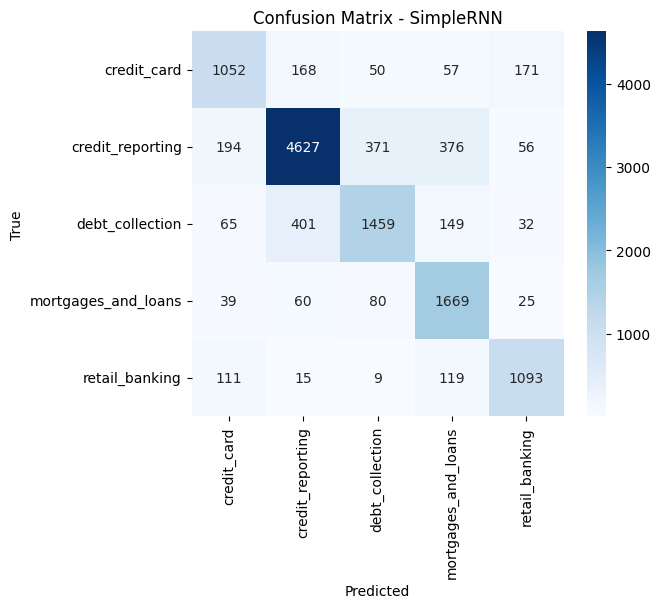

In [34]:
rnn_model = train_and_eval(layers.SimpleRNN, "SimpleRNN")
import json
json.dump(results, open("/kaggle/working/results.json", "w"), indent=2)

            accuracy  precision_macro  recall_macro  f1_macro  train_time_sec
SimpleRNN     0.7953           0.7674        0.7841    0.7731            70.0
LSTM          0.8206           0.7931        0.8398    0.8122            74.0
GRU           0.8373           0.8067        0.8508    0.8257            47.0
DistilBERT    0.8527           0.8287        0.8609    0.8433          2397.0


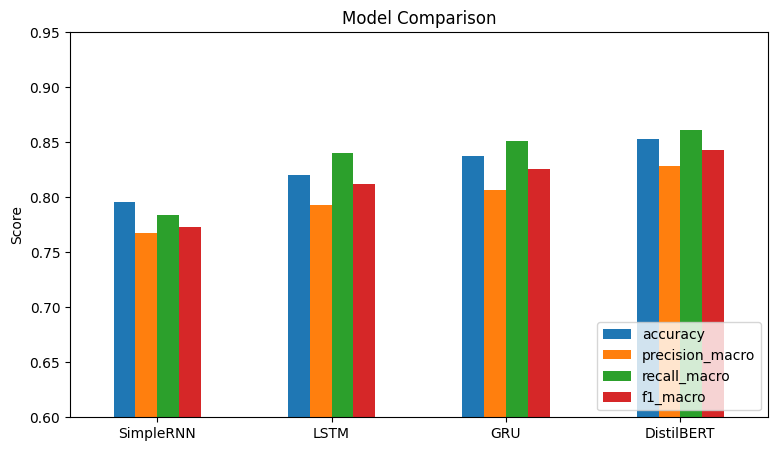

                     SimpleRNN   LSTM    GRU  DistilBERT
credit_card              0.711  0.770  0.780       0.799
credit_reporting         0.849  0.853  0.872       0.883
debt_collection          0.716  0.765  0.786       0.796
mortgages_and_loans      0.787  0.822  0.833       0.854
retail_banking           0.802  0.852  0.858       0.885


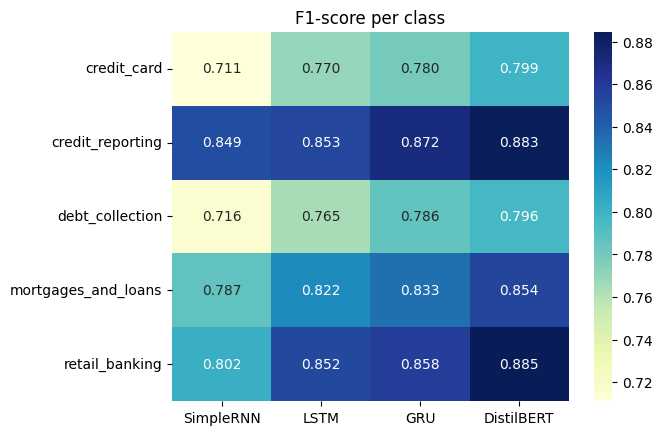

In [35]:
order = ["SimpleRNN", "LSTM", "GRU", "DistilBERT"]
comp = pd.DataFrame(results).T.loc[order]
comp = comp[['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'train_time_sec']]
print(comp)
comp.to_csv("/kaggle/working/model_comparison.csv")

comp[['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']].plot(
    kind='bar', figsize=(9, 5), ylim=(0.6, 0.95))
plt.title("Model Comparison"); plt.ylabel("Score"); plt.xticks(rotation=0)
plt.legend(loc='lower right'); plt.show()

rows = {}
for name in order:
    _, _, f, _ = precision_recall_fscore_support(y_test, preds_store[name], zero_division=0)
    rows[name] = f
per_class = pd.DataFrame(rows, index=le.classes_)
print(per_class.round(3))
sns.heatmap(per_class, annot=True, fmt='.3f', cmap='YlGnBu')
plt.title("F1-score per class"); plt.show()

In [36]:
import re, nltk, torch
nltk.download('stopwords'); nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = [lemmatizer.lemmatize(w) for w in text.split() if w not in stop_words]
    return ' '.join(words)

bert.eval()

def predict(text, top_k=3):
    cleaned = clean_text(text)
    enc = hf_tok(cleaned, truncation=True, max_length=256, return_tensors='pt').to(bert.device)
    with torch.no_grad():
        logits = bert(**enc).logits
    probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    order = probs.argsort()[::-1][:top_k]
    return [(le.classes_[i], round(float(probs[i]), 4)) for i in order]

tests = [
    "I was charged a late fee on my credit card even though I paid before the due date. Capital One refuses to remove it.",
    "A debt collector keeps calling me at work about a debt I do not owe and will not send me written validation.",
    "There is an account on my Experian credit report that does not belong to me and they refuse to remove it after my dispute.",
    "My bank froze my checking account without notice and I cannot access my money.",
    "My mortgage servicer misapplied my payments and now says I am behind on my loan.",
]
for t in tests:
    print(t[:70], "...")
    print("  ->", predict(t), "\n")

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


I was charged a late fee on my credit card even though I paid before t ...
  -> [('credit_card', 0.9717), ('credit_reporting', 0.0145), ('debt_collection', 0.0083)] 

A debt collector keeps calling me at work about a debt I do not owe an ...
  -> [('debt_collection', 0.9876), ('credit_reporting', 0.0074), ('mortgages_and_loans', 0.0032)] 

There is an account on my Experian credit report that does not belong  ...
  -> [('credit_reporting', 0.9519), ('debt_collection', 0.0434), ('credit_card', 0.0024)] 

My bank froze my checking account without notice and I cannot access m ...
  -> [('retail_banking', 0.9897), ('credit_card', 0.0046), ('mortgages_and_loans', 0.003)] 

My mortgage servicer misapplied my payments and now says I am behind o ...
  -> [('mortgages_and_loans', 0.9866), ('debt_collection', 0.0066), ('credit_reporting', 0.0052)] 



In [37]:
print(predict("A collector reported a debt on my credit report after I already paid it off, and the bureau will not delete it."))
print(predict("I disputed a charge on my credit card and the bank closed my checking account."))

[('debt_collection', 0.874), ('credit_reporting', 0.1201), ('mortgages_and_loans', 0.0032)]
[('credit_card', 0.5211), ('retail_banking', 0.4342), ('credit_reporting', 0.0203)]


In [41]:
import shutil
shutil.make_archive("/kaggle/working/distilbert_final", "zip", "/kaggle/working/distilbert_final")
shutil.make_archive("/kaggle/working/keras_models", "zip", "/kaggle/working", "gru_dummy") if False else None
print("done")

done
